In [1]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, MACCSkeys, RDKFingerprint
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error

In [2]:
# Load dataset
df = pd.read_csv('bandgap.csv')

# Splitting the DataFrame into 80% train and 20% test
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# Remove rows with invalid SMILES
df = df.dropna(subset=['Smiles'])

In [29]:
df

,Smiles,BG,DOI
0,c1(cc(c(cc1OC)c1sc(cc1)c1n(C)c(=O)c2c1c(=O)n(c...,1.69,10.1016/j.solener.2017.12.042
1,c1(cc(c(cc1F)c1sc(cc1)c1n(C)c(=O)c2c1c(=O)n(c2...,1.76,10.1016/j.solener.2017.12.042
2,c1(ccc(cc1)c1ccc(s1)c1ccc(s1)C=C1C(=O)NC(=O)NC...,1.59,10.1016/j.solener.2019.11.073
3,c1(ccc(cc1)c1ccc(s1)c1ccc(s1)/C=C/1\C(=O)N(C(=...,1.77,10.1016/j.solener.2019.11.073
4,c1(c2c(c(c3c1sc(c3)c1cc3c(cc1)c1c(n3C)cc(s1)c1...,1.50,10.1016/j.dyepig.2018.07.009
...,...,...,...
295,c1(=O)c2c3c(c(=O)n1C)ccc1c3c(c3c1c(c1c(c4cccc5...,2.47,10.1002/ajoc.201700203
296,c12c3c(c4c(c1c1ccc5c6c1c2ccc6c(=O)n(c5=O)C)c1c...,2.20,10.1002/anie.201207608
297,c12c3c(=C4C=CC(=[S@@]4O2)c2cccs2)cc2c(=O)n(c4c...,1.68,10.1021/cm2019668
298,c12c3c(=C4C=CC(=[S@@]4O2)c2ccc(s2)c2cccs2)cc2c...,1.46,10.1021/cm2019668


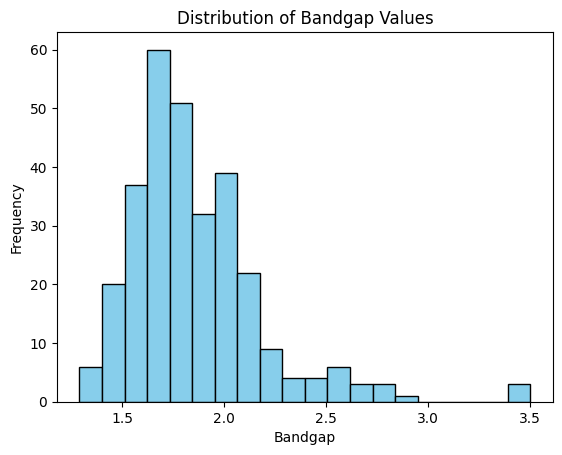

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot histogram of bandgap values
plt.hist(df['BG'], bins=20, color='skyblue', edgecolor='black')
plt.xlabel('Bandgap')
plt.ylabel('Frequency')
plt.title('Distribution of Bandgap Values')
plt.show()


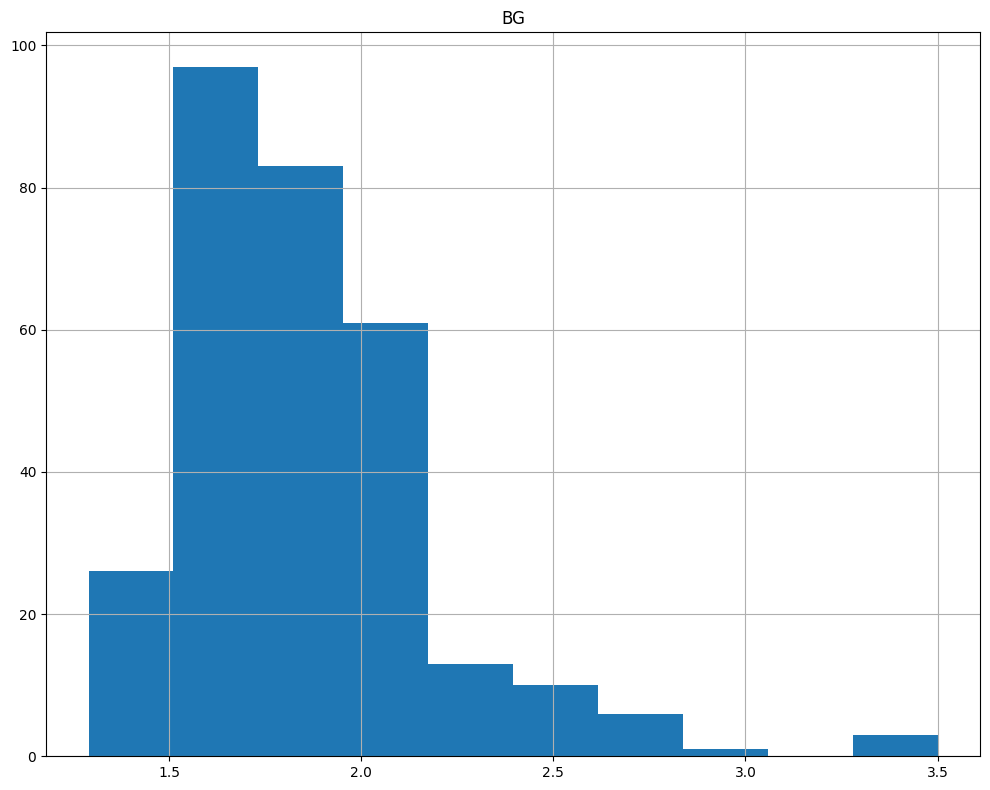

In [4]:
# Plot histograms of numerical features
df.hist(figsize=(10, 8))
plt.tight_layout()
plt.show()

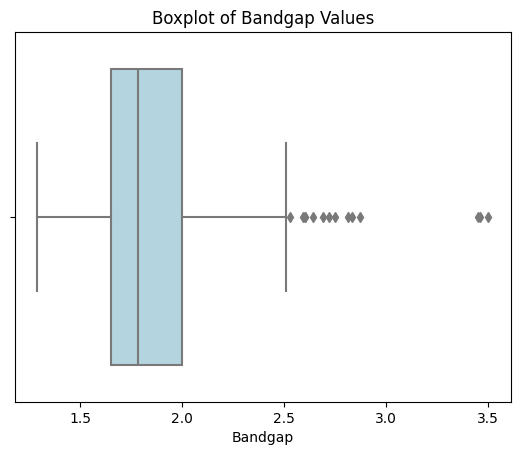

In [5]:
# Create boxplot for bandgap values
sns.boxplot(x=df['BG'], color='lightblue')
plt.xlabel('Bandgap')
plt.title('Boxplot of Bandgap Values')
plt.show()

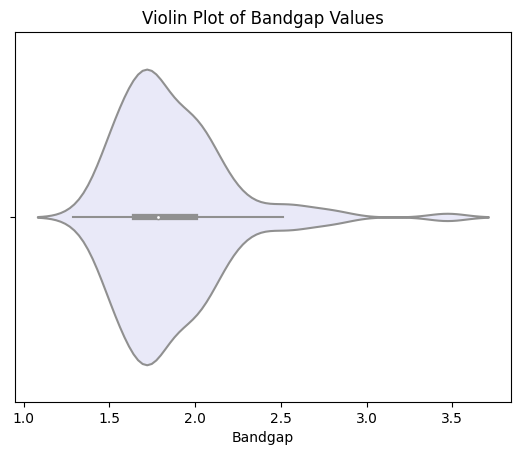

In [6]:
# Create violin plot for bandgap values
sns.violinplot(x=df['BG'], color='lavender')
plt.xlabel('Bandgap')
plt.title('Violin Plot of Bandgap Values')
plt.show()

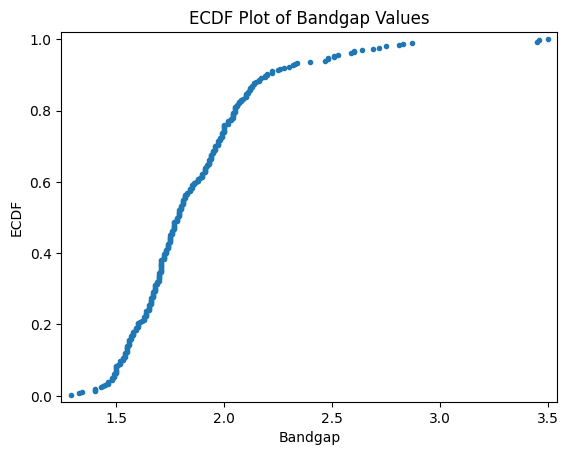

In [7]:
import numpy as np

# Create ECDF plot for bandgap values
sorted_data = np.sort(df['BG'])
y = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
plt.plot(sorted_data, y, marker='.', linestyle='none')
plt.xlabel('Bandgap')
plt.ylabel('ECDF')
plt.title('ECDF Plot of Bandgap Values')
plt.margins(0.02)  # Add small margins to the plot
plt.show()

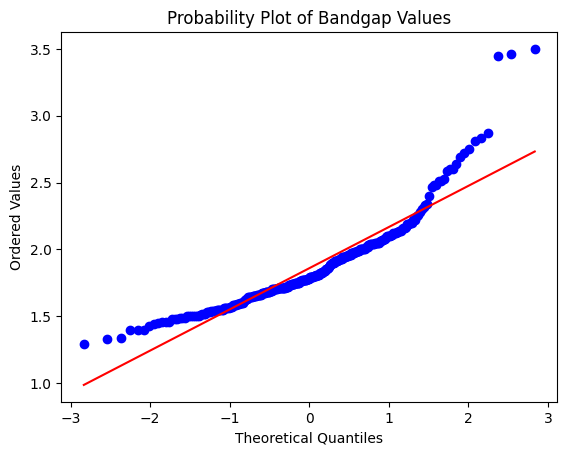

In [8]:
import scipy.stats as stats

# Create probability plot for bandgap values against a normal distribution
stats.probplot(df['BG'], dist="norm", plot=plt)
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Ordered Values')
plt.title('Probability Plot of Bandgap Values')
plt.show()

In [9]:
# Function to compute MACCS keys
def compute_maccs_keys(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        return MACCSkeys.GenMACCSKeys(mol)
    else:
        return None

# Function to compute RDKit fingerprints
def compute_rdkit_fingerprint(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        return Chem.RDKFingerprint(mol)
    else:
        return None

# Function to compute Morgan fingerprints
def compute_morgan_fingerprint(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        return AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=1024)  # Morgan fingerprint with radius 2 and 1024 bits
    else:
        return None

# Function to compute AtomPair fingerprints
def compute_atompair_fingerprint(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        return AllChem.GetHashedAtomPairFingerprintAsBitVect(mol)
    else:
        return None

In [10]:
morgan_fps = []
maccs_fps = []
rdkit_fps = []
atompair_fps = []
valid_indices = []  # Track indices of valid SMILES
for i, smi in enumerate(df['Smiles']):
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        morgan_fps.append(compute_morgan_fingerprint(smi))
        maccs_fps.append(compute_maccs_keys(smi))
        rdkit_fps.append(compute_rdkit_fingerprint(smi))
        atompair_fps.append(compute_atompair_fingerprint(smi))
        valid_indices.append(i)

[14:56:53] Can't kekulize mol.  Unkekulized atoms: 11 13 14 15 16 17 18
[14:56:53] Can't kekulize mol.  Unkekulized atoms: 25 27 28 29 30 31 32
[14:56:53] Explicit valence for atom # 5 B, 4, is greater than permitted
[14:56:55] Explicit valence for atom # 16 N, 4, is greater than permitted
[14:56:55] Explicit valence for atom # 5 B, 4, is greater than permitted
[14:56:55] Explicit valence for atom # 5 B, 4, is greater than permitted
[14:56:55] Explicit valence for atom # 5 B, 4, is greater than permitted
[14:56:55] Explicit valence for atom # 5 B, 4, is greater than permitted
[14:56:55] Explicit valence for atom # 5 B, 4, is greater than permitted
[14:56:55] Explicit valence for atom # 16 C, 5, is greater than permitted
[14:56:56] Can't kekulize mol.  Unkekulized atoms: 40
[14:56:56] Explicit valence for atom # 27 B, 4, is greater than permitted
[14:56:56] Explicit valence for atom # 17 B, 4, is greater than permitted
[14:56:56] Explicit valence for atom # 17 B, 4, is greater than perm

In [11]:
# Filter dataframe based on valid indices
df = df.iloc[valid_indices]

# Split the dataset into training and testing sets for each type of fingerprint
X_morgan_train, X_morgan_test, y_train, y_test = train_test_split(morgan_fps, df['BG'], test_size=0.2, random_state=42)
X_maccs_train, X_maccs_test, _, _ = train_test_split(maccs_fps, df['BG'], test_size=0.2, random_state=42)
X_rdkit_train, X_rdkit_test, _, _ = train_test_split(rdkit_fps, df['BG'], test_size=0.2, random_state=42)
X_atompair_train, X_atompair_test, _, _ = train_test_split(atompair_fps, df['BG'], test_size=0.2, random_state=42)

In [27]:
X_morgan_train

In [28]:
for X_train, X_test, fingerprint_type in [(X_morgan_train, X_morgan_test, 'Morgan'),
                                              (X_maccs_train, X_maccs_test, 'MACCS'),
                                              (X_rdkit_train, X_rdkit_test, 'RDKit')]:
    print(X_train)
    break

[<rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x7f39c02e12e0>, <rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x7f39c03460b0>, <rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x7f39c0348cf0>, <rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x7f39c02d3430>, <rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x7f39c02d27b0>, <rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x7f39c02dfba0>, <rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x7f39c03425f0>, <rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x7f39c02d6eb0>, <rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x7f39c02d2b30>, <rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x7f39c0343eb0>, <rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x7f39c03435f0>, <rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x7f39c034e7b0>, <rdkit.DataStructs.cDataStructs.ExplicitBitVect object at 0x7f39c03475f0>, <rdkit.DataStructs.cData

In [12]:
# Initialize models
models = {
    'Random Forest': RandomForestRegressor(random_state=42),
    'SVR': SVR(kernel='linear'),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42),
    'KNeighbors': KNeighborsRegressor()
}

# Hyperparameter tuning
param_grid = {
    'Random Forest': {'n_estimators': [50, 100, 200], 'max_depth': [None, 10, 20]},
    'SVR': {'C': [0.1, 1, 10], 'epsilon': [0.1, 0.01]},
    'Gradient Boosting': {'n_estimators': [50, 100, 200], 'max_depth': [3, 5, 10], 'learning_rate': [0.1, 0.01]},
    'AdaBoost': {'n_estimators': [50, 100, 200], 'learning_rate': [0.1, 0.01]},
    'XGBoost': {'n_estimators': [50, 100, 200], 'max_depth': [3, 5, 10], 'learning_rate': [0.1, 0.01]},
    'KNeighbors': {'n_neighbors': [3, 5, 10]}
}

results = {}
# Hyperparameter tuning
best_params = {}

for name, model in models.items():
    for X_train, X_test, fingerprint_type in [(X_morgan_train, X_morgan_test, 'Morgan'),
                                              (X_maccs_train, X_maccs_test, 'MACCS'),
                                              (X_rdkit_train, X_rdkit_test, 'RDKit')]:
        grid_search = GridSearchCV(model, param_grid[name], scoring='neg_mean_absolute_error', cv=5)
        grid_search.fit(X_train, y_train)
        best_params[name] = grid_search.best_params_
        best_model = grid_search.best_estimator_
        y_pred = best_model.predict(X_test)
        r2 = r2_score(y_test, y_pred)
        mae = mean_absolute_error(y_test, y_pred)
        if name not in results:
            results[name] = {}
        print({'R^2': r2, 'MAE': mae})
        # results[name][fingerprint_type] = {'R^2': r2, 'MAE': mae}
        results[name][fingerprint_type] = {'R^2': r2, 'MAE': mae, 'Predicted': y_pred, 'Actual': y_test,'Model':best_model}

{'R^2': 0.6974342109850251, 'MAE': 0.1424826065162907}
{'R^2': 0.5401521473642974, 'MAE': 0.15405545368996956}
{'R^2': 0.727760192777355, 'MAE': 0.13287775271512112}
{'R^2': 0.6639654518950061, 'MAE': 0.1563659178534716}
{'R^2': 0.4406030705191546, 'MAE': 0.1757286186180611}
{'R^2': 0.781667242739822, 'MAE': 0.12883991598849698}
{'R^2': 0.7490647115359201, 'MAE': 0.14046033880861586}
{'R^2': 0.5049399814719036, 'MAE': 0.17006978638401243}
{'R^2': 0.7729190606320497, 'MAE': 0.12514152422997757}
{'R^2': 0.5872713439322648, 'MAE': 0.16923402069992402}
{'R^2': 0.5401010434243343, 'MAE': 0.17259107630998147}
{'R^2': 0.7615031642577765, 'MAE': 0.13169457093839998}
{'R^2': 0.597436308098658, 'MAE': 0.15641129410057739}
{'R^2': 0.6792751288071891, 'MAE': 0.14458989611843173}
{'R^2': 0.7639416310262124, 'MAE': 0.1313481959125452}
{'R^2': 0.700618988140673, 'MAE': 0.14543859649122806}
{'R^2': 0.48315656690821496, 'MAE': 0.16957894736842105}
{'R^2': 0.7428855140418531, 'MAE': 0.13607017543859645}

In [30]:
best_params

{'Random Forest': {'max_depth': None, 'n_estimators': 50},
 'SVR': {'C': 1, 'epsilon': 0.1},
 'Gradient Boosting': {'learning_rate': 0.1,
  'max_depth': 3,
  'n_estimators': 50},
 'AdaBoost': {'learning_rate': 0.1, 'n_estimators': 50},
 'XGBoost': {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200},
 'KNeighbors': {'n_neighbors': 5}}

In [13]:
import pickle
with open('best_params.pkl', 'wb') as f:
    pickle.dump(best_params, f)

In [14]:
# In the other file, load the best_params
with open('best_params.pkl', 'rb') as f:
    best_params_other_file = pickle.load(f)

In [15]:
best_params_other_file

{'Random Forest': {'max_depth': None, 'n_estimators': 50},
 'SVR': {'C': 1, 'epsilon': 0.1},
 'Gradient Boosting': {'learning_rate': 0.1,
  'max_depth': 3,
  'n_estimators': 50},
 'AdaBoost': {'learning_rate': 0.1, 'n_estimators': 50},
 'XGBoost': {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200},
 'KNeighbors': {'n_neighbors': 5}}

In [16]:
# Print results
print("Results for different types of fingerprints:")
for name, model_results in results.items():
    print(f"{name}:")
    for fingerprint_type, metrics in model_results.items():
        print(f"  {fingerprint_type}: R^2 = {metrics['R^2']:.4f}, MAE = {metrics['MAE']:.4f}")

Results for different types of fingerprints:
Random Forest:
  Morgan: R^2 = 0.6974, MAE = 0.1425
  MACCS: R^2 = 0.5402, MAE = 0.1541
  RDKit: R^2 = 0.7278, MAE = 0.1329
SVR:
  Morgan: R^2 = 0.6640, MAE = 0.1564
  MACCS: R^2 = 0.4406, MAE = 0.1757
  RDKit: R^2 = 0.7817, MAE = 0.1288
Gradient Boosting:
  Morgan: R^2 = 0.7491, MAE = 0.1405
  MACCS: R^2 = 0.5049, MAE = 0.1701
  RDKit: R^2 = 0.7729, MAE = 0.1251
AdaBoost:
  Morgan: R^2 = 0.5873, MAE = 0.1692
  MACCS: R^2 = 0.5401, MAE = 0.1726
  RDKit: R^2 = 0.7615, MAE = 0.1317
XGBoost:
  Morgan: R^2 = 0.5974, MAE = 0.1564
  MACCS: R^2 = 0.6793, MAE = 0.1446
  RDKit: R^2 = 0.7639, MAE = 0.1313
KNeighbors:
  Morgan: R^2 = 0.7006, MAE = 0.1454
  MACCS: R^2 = 0.4832, MAE = 0.1696
  RDKit: R^2 = 0.7429, MAE = 0.1361


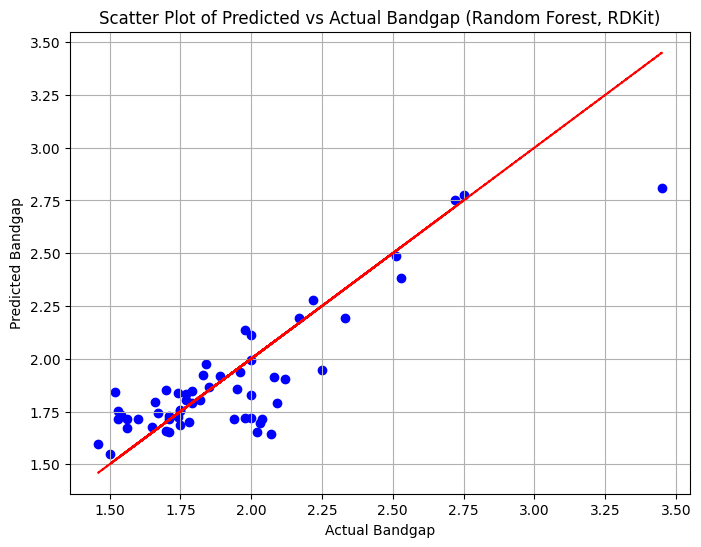

In [17]:
# Choose the best model based on R^2 or MAE for a specific fingerprint type
best_model_name = 'Random Forest'  # Example: Choose Random Forest as the best model
fingerprint_type = 'RDKit'  # Example: Choose RDKit fingerprint type

# Extract predicted and actual bandgap values for the chosen model and fingerprint type
predicted_values = results[best_model_name][fingerprint_type]['Predicted']
actual_values = results[best_model_name][fingerprint_type]['Actual']

# Create a scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(actual_values, predicted_values, color='blue')
plt.plot(actual_values, actual_values, color='red', linestyle='--')  # Add a diagonal line for reference
plt.title(f'Scatter Plot of Predicted vs Actual Bandgap ({best_model_name}, {fingerprint_type})')
plt.xlabel('Actual Bandgap')
plt.ylabel('Predicted Bandgap')
plt.grid(True)
plt.show()

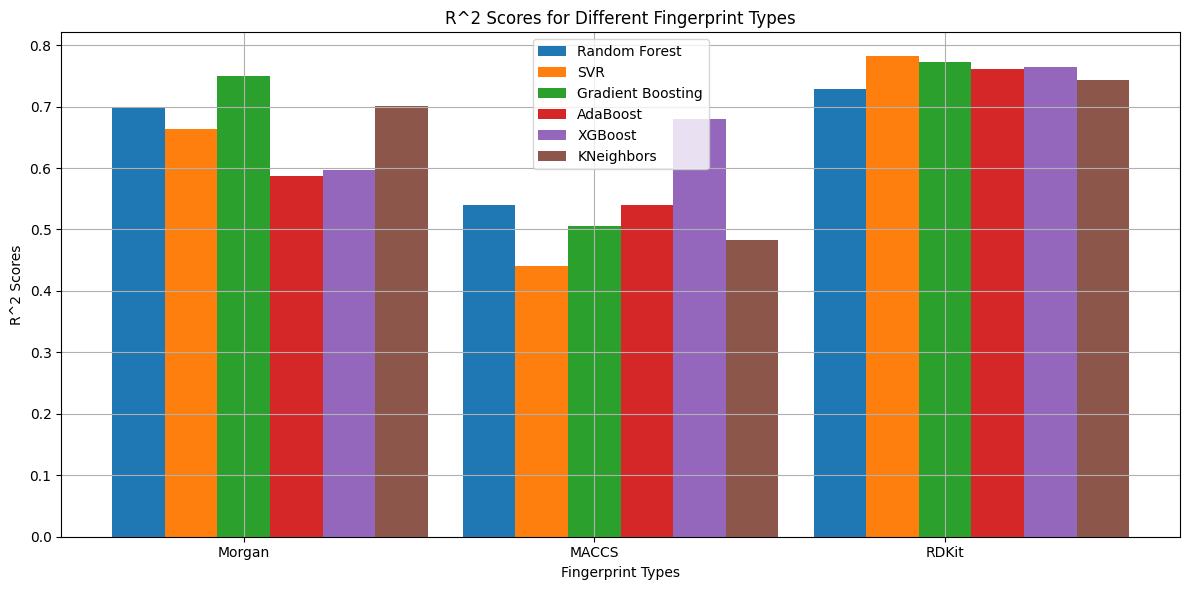

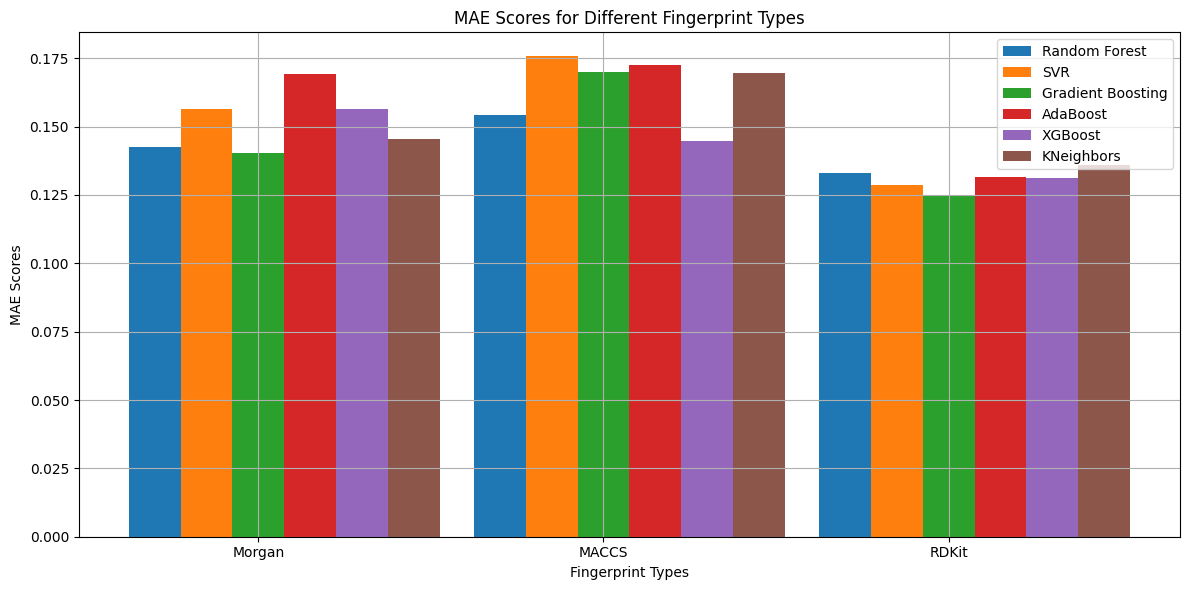

In [18]:
import matplotlib.pyplot as plt

# Results data
algorithms = ['Random Forest', 'SVR', 'Gradient Boosting', 'AdaBoost', 'XGBoost', 'KNeighbors']
fingerprints = ['Morgan', 'MACCS', 'RDKit']

r2_scores = {
    'Random Forest': [0.6974, 0.5402, 0.7278],
    'SVR': [0.6640, 0.4406, 0.7817],
    'Gradient Boosting': [0.7491, 0.5049, 0.7729],
    'AdaBoost': [0.5873, 0.5401, 0.7615],
    'XGBoost': [0.5974, 0.6793, 0.7639],
    'KNeighbors': [0.7006, 0.4832, 0.7429]
}

mae_scores = {
    'Random Forest': [0.1425, 0.1541, 0.1329],
    'SVR': [0.1564, 0.1757, 0.1288],
    'Gradient Boosting': [0.1405, 0.1701, 0.1251],
    'AdaBoost': [0.1692, 0.1726, 0.1317],
    'XGBoost': [0.1564, 0.1446, 0.1313],
    'KNeighbors': [0.1454, 0.1696, 0.1361]
}

# Plotting R^2 scores
plt.figure(figsize=(12, 6))
for i, algorithm in enumerate(algorithms):
    plt.bar([x + i * 0.15 for x in range(len(fingerprints))], r2_scores[algorithm], width=0.15, label=algorithm)

plt.xlabel('Fingerprint Types')
plt.ylabel('R^2 Scores')
plt.xticks([x + 0.3 for x in range(len(fingerprints))], fingerprints)
plt.title('R^2 Scores for Different Fingerprint Types')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plotting MAE scores
plt.figure(figsize=(12, 6))
for i, algorithm in enumerate(algorithms):
    plt.bar([x + i * 0.15 for x in range(len(fingerprints))], mae_scores[algorithm], width=0.15, label=algorithm)

plt.xlabel('Fingerprint Types')
plt.ylabel('MAE Scores')
plt.xticks([x + 0.3 for x in range(len(fingerprints))], fingerprints)
plt.title('MAE Scores for Different Fingerprint Types')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [19]:
from sklearn.linear_model import RidgeCV
from sklearn.svm import LinearSVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import StackingRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression

# Use best parameters to initialize models
models_with_best_params = {}
for name, params in best_params.items():
    if name == 'Random Forest':
        models_with_best_params[name] = RandomForestRegressor(random_state=42, **params)
    elif name == 'SVR':
        models_with_best_params[name] = SVR(kernel='linear', **params)
    elif name == 'Gradient Boosting':
        models_with_best_params[name] = GradientBoostingRegressor(random_state=42, **params)
    elif name == 'AdaBoost':
        models_with_best_params[name] = AdaBoostRegressor(random_state=42, **params)
    elif name == 'XGBoost':
        models_with_best_params[name] = XGBRegressor(random_state=42, **params)
    elif name == 'KNeighbors':
        models_with_best_params[name] = KNeighborsRegressor(**params)

# Initialize StackingRegressor with models using best parameters
estimators = [(name, model) for name, model in models_with_best_params.items()]
reg = StackingRegressor(
    estimators=estimators,
    final_estimator=LinearRegression()
)

results = {}
for X_train, X_test, fingerprint_type in [(X_morgan_train, X_morgan_test, 'Morgan'),
                                              (X_maccs_train, X_maccs_test, 'MACCS'),
                                              (X_rdkit_train, X_rdkit_test, 'RDKit')]:
    reg.fit(X_train, y_train)
    y_pred = reg.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    
    if name not in results:
        results[name] = {}
    print({'R^2': r2, 'MAE': mae})
    # results[name][fingerprint_type] = {'R^2': r2, 'MAE': mae}
    results[name][fingerprint_type] = {'R^2': r2, 'MAE': mae, 'Predicted': y_pred, 'Actual': y_test,'Model':best_model}



{'R^2': 0.731086099368923, 'MAE': 0.14052762592785906}
{'R^2': 0.5908466149280149, 'MAE': 0.1528283208479905}
{'R^2': 0.8082995726096034, 'MAE': 0.1198967147542694}


In [20]:
# Print results
print("Results for different types of fingerprints:")
for name, model_results in results.items():
    print(f"{name}:")
    for fingerprint_type, metrics in model_results.items():
        print(f"  {fingerprint_type}: R^2 = {metrics['R^2']:.4f}, MAE = {metrics['MAE']:.4f}")

Results for different types of fingerprints:
KNeighbors:
  Morgan: R^2 = 0.7311, MAE = 0.1405
  MACCS: R^2 = 0.5908, MAE = 0.1528
  RDKit: R^2 = 0.8083, MAE = 0.1199


In [21]:
models_with_best_params = {}
for name, params in best_params.items():
    print(name,params)

Random Forest {'max_depth': None, 'n_estimators': 50}
SVR {'C': 1, 'epsilon': 0.1}
Gradient Boosting {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}
AdaBoost {'learning_rate': 0.1, 'n_estimators': 50}
XGBoost {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200}
KNeighbors {'n_neighbors': 5}


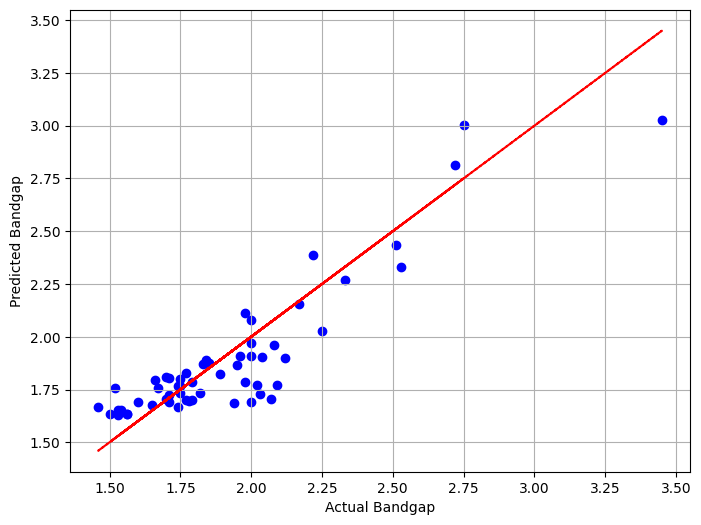

In [22]:

y_pred = reg.predict(X_test)

# Create a scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue')
plt.plot(y_test, y_test, color='red', linestyle='--')  # Add a diagonal line for reference
# plt.title(f'Scatter Plot of Predicted vs Actual Bandgap ({best_model_name}, {fingerprint_type})')
plt.xlabel('Actual Bandgap')
plt.ylabel('Predicted Bandgap')
plt.grid(True)
plt.show()
    

In [23]:
#----------------------------------------------------
from matplotlib import pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sn

In [24]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

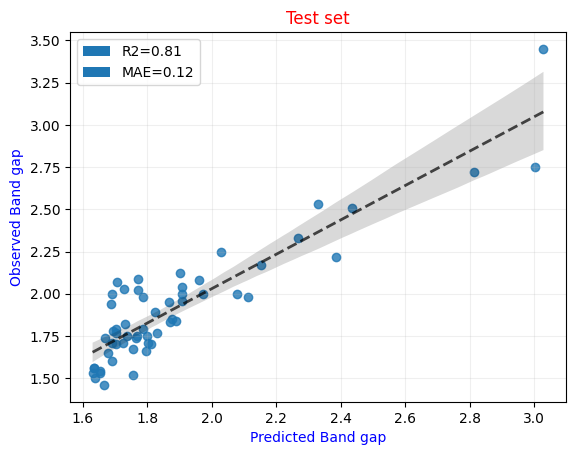

In [25]:
sn.regplot(x=y_pred , y=y_test,line_kws={"lw":2,'ls':'--','color':'black',"alpha":0.7})
plt.xlabel('Predicted Band gap', color='blue')
plt.ylabel('Observed Band gap', color ='blue')
plt.title("Test set", color='red')
plt.grid(alpha=0.2)
R2 = mpatches.Patch(label="R2={:04.2f}".format(r2))
MAE = mpatches.Patch(label="MAE={:04.2f}".format(mae))
plt.legend(handles=[R2, MAE])

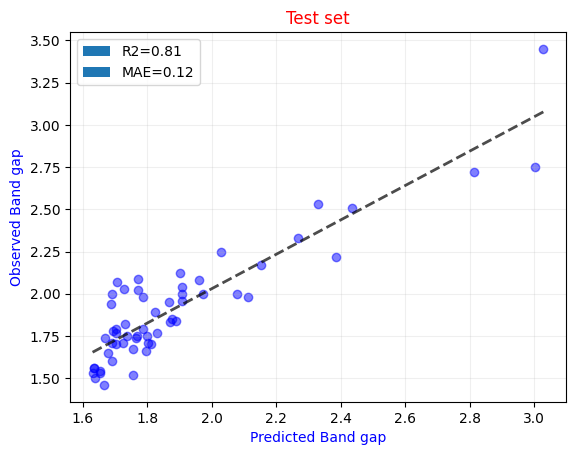

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches

# Plot
sns.regplot(x=y_pred, y=y_test, scatter_kws={"color": "blue", "alpha":0.5}, line_kws={"lw":2,'ls':'--','color':'black',"alpha":0.7}, ci=None)
plt.xlabel('Predicted Band gap', color='blue')
plt.ylabel('Observed Band gap', color='blue')
plt.title("Test set", color='red')
plt.grid(alpha=0.2)
R2 = mpatches.Patch(label="R2={:04.2f}".format(r2))
MAE = mpatches.Patch(label="MAE={:04.2f}".format(mae))
plt.legend(handles=[R2, MAE])
plt.show()

